# Ruthvik_Nath_Bandari_Phishing_Detective

**AI for Cybersecurity, Module 4 Lab: Fraud Detection with Threat Intelligence** · Ruthvik Nath Bandari · Northeastern University

The brief names two Kaggle datasets, so this notebook covers both:

| Part | Dataset | What it does |
|---|---|---|
| Step 1A | [Phishing Emails](https://www.kaggle.com/datasets/subhajournal/phishingemails) (18,650 emails) | Count phishing vs normal emails, examine examples, train a small text "phishing detective" |
| Steps 1B–3 | [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) (284,807 transactions, 0.17% fraud) | EDA, SMOTE, three tuned models, a voting ensemble, feature importance, a fraud dashboard, error analysis, a threat intelligence report and real-time scoring |

Both datasets download straight from Kaggle with `kagglehub` (pre-installed in Colab, no login needed).
Everything is seeded (`SEED = 42`). A full *Runtime → Run all* takes about 25 minutes on a free Colab CPU.

In [1]:
# Colab ships kagglehub, xgboost and imbalanced-learn; this installs them only if one is missing.
import importlib.util, subprocess, sys
missing = [pkg for pkg, mod in [("kagglehub", "kagglehub"), ("xgboost", "xgboost"), ("imbalanced-learn", "imblearn")]
           if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

import kagglehub
import sklearn, xgboost, imblearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from joblib import Parallel, delayed
from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.metrics import (classification_report, confusion_matrix, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve, precision_recall_curve)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 120)
print(f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | imbalanced-learn {imblearn.__version__}")

scikit-learn 1.6.1 | xgboost 3.4.1 | imbalanced-learn 0.14.2


## Step 1A · Phishing email analysis

The brief's Step 1 asks for the phishing email dataset: load it, count phishing versus normal emails and examine examples.

In [2]:
phish_dir = Path(kagglehub.dataset_download("subhajournal/phishingemails/versions/1"))
emails = pd.read_csv(phish_dir / "Phishing_Email.csv").drop(columns=["Unnamed: 0"])
missing_text = emails["Email Text"].isna().sum()
emails = emails.dropna(subset=["Email Text"]).drop_duplicates(subset=["Email Text"])
emails["is_phishing"] = (emails["Email Type"] == "Phishing Email").astype(int)

print(f"Loaded {len(emails):,} unique emails (dropped {missing_text} empty rows and duplicate texts)")
counts = emails["Email Type"].value_counts().to_frame("emails")
counts["share"] = counts["emails"] / counts["emails"].sum()
counts

100%|██████████| 18.0M/18.0M [00:02<00:00, 9.26MB/s]

Extracting files...


Loaded 17,537 unique emails (dropped 16 empty rows and duplicate texts)


,emails,share
Email Type,,
Safe Email,10979,0.6260
Phishing Email,6558,0.3740


In [3]:
def preview(text, n=220):
    return re.sub(r"\s+", " ", str(text))[:n] + "..."

examples = pd.concat([emails[emails.is_phishing == 1].sample(2, random_state=SEED),
                      emails[emails.is_phishing == 0].sample(2, random_state=SEED)])
for _, row in examples.iterrows():
    print(f"[{row['Email Type']}] {preview(row['Email Text'])}\n")

[Phishing Email] all graphics software available , cheap oem versions . good morning , we we offer latest oem packages of all graphics and publishing software from corei , macromedia , adobe and others . $ 80 adobe photoshop 8 . 0 / cs $...

[Phishing Email] woww . . 8 o - % off paliourg i can ' t believe this incrediible priicess . . pain relief ( from $ 99 ) ( viicodin , hydrocodoone , valliium ) men ' s pillls ( from $ 140 ) ( viiagra , leviitra ) weight losss ( from $ 14...

[Safe Email]  Paul> I suspect the best answer is to make the DBM implementation Paul> configurable via bayescustomize.ini (with the default being Paul> anydbm).I think you might want to specify the database open function instead of j...

[Safe Email] re : file cabinet for mike roberts kevin g moore 11 / 20 / 2000 12 : 14 pm to : mike a roberts / hou / ect @ ect cc : subject : re : file cabinet for mike roberts this file cabinet will also be located on the 32 nd floor...



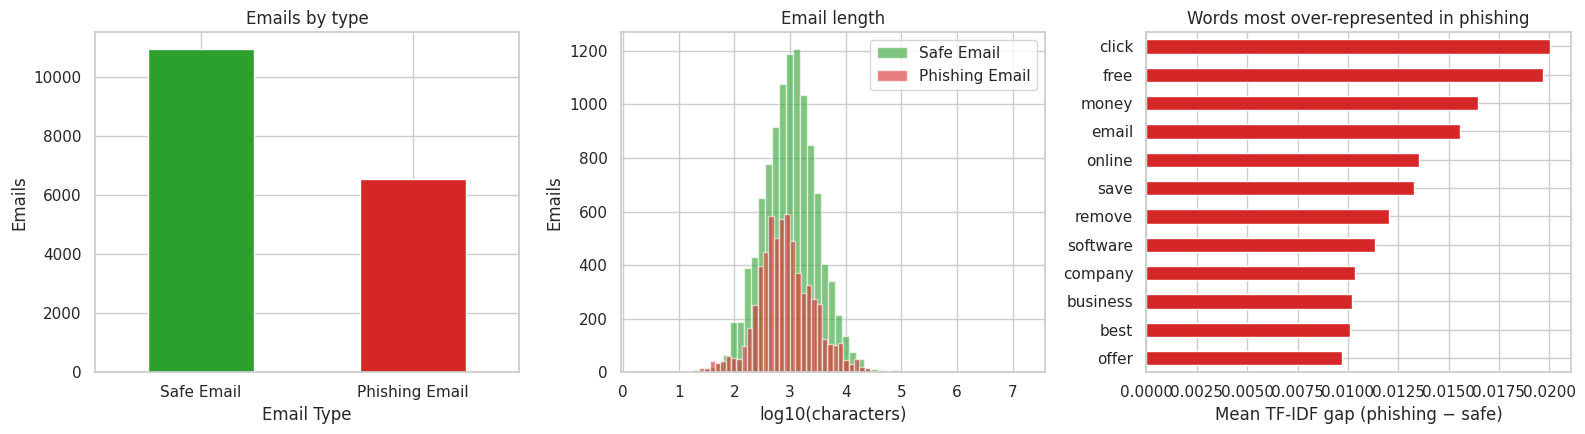

Words most typical of phishing: click, free, money, email, online, save, remove, software, company, business, best, offer
Words most typical of safe email: enron, ect, linux, language, hou, university, date, vince, rpm, wrote, linguistics, url


,median_chars,share_with_url,mean_exclamations
Email Type,,,
Phishing Email,763.5000,0.3631,3.4289
Safe Email,1021.0000,0.4041,1.9433


In [4]:
emails["n_chars"] = emails["Email Text"].str.len()
emails["has_url"] = emails["Email Text"].str.contains(r"http|www\.", case=False, regex=True)
emails["n_exclaim"] = emails["Email Text"].str.count("!")

summary = emails.groupby("Email Type").agg(median_chars=("n_chars", "median"),
                                           share_with_url=("has_url", "mean"),
                                           mean_exclamations=("n_exclaim", "mean"))

vec = TfidfVectorizer(stop_words="english", max_features=20000, min_df=5, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
tf = vec.fit_transform(emails["Email Text"])
vocab = np.array(vec.get_feature_names_out())
gap = np.asarray(tf[emails.is_phishing.values == 1].mean(axis=0) - tf[emails.is_phishing.values == 0].mean(axis=0)).ravel()
top_phish, top_safe = vocab[np.argsort(gap)[-12:][::-1]], vocab[np.argsort(gap)[:12]]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
emails["Email Type"].value_counts().plot.bar(ax=axes[0], color=["tab:green", "tab:red"], rot=0)
axes[0].set(title="Emails by type", ylabel="Emails")
for label, color in [("Safe Email", "tab:green"), ("Phishing Email", "tab:red")]:
    axes[1].hist(np.log10(emails.loc[emails["Email Type"] == label, "n_chars"] + 1), bins=50, alpha=0.6, color=color, label=label)
axes[1].set(title="Email length", xlabel="log10(characters)", ylabel="Emails"); axes[1].legend()
words = pd.Series(gap[np.argsort(gap)[-12:]], index=vocab[np.argsort(gap)[-12:]])
words.plot.barh(ax=axes[2], color="tab:red")
axes[2].set(title="Words most over-represented in phishing", xlabel="Mean TF-IDF gap (phishing − safe)")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig0_phishing_eda.png", dpi=200); plt.show()

print("Words most typical of phishing:", ", ".join(top_phish))
print("Words most typical of safe email:", ", ".join(top_safe))
summary

In [5]:
# A small "phishing detective": TF-IDF features + logistic regression, stratified hold-out test
Xe_tr, Xe_te, ye_tr, ye_te = train_test_split(emails["Email Text"], emails["is_phishing"], test_size=0.2,
                                              stratify=emails["is_phishing"], random_state=SEED)
phish_model = Pipeline([("tfidf", TfidfVectorizer(stop_words="english", max_features=30000, ngram_range=(1, 2), min_df=3)),
                        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
phish_model.fit(Xe_tr, ye_tr)
pe = phish_model.predict_proba(Xe_te)[:, 1]
print(classification_report(ye_te, (pe >= 0.5).astype(int), target_names=["Safe", "Phishing"], digits=4))
print(f"Phishing detective AUC-ROC: {roc_auc_score(ye_te, pe):.4f}")

              precision    recall  f1-score   support

        Safe     0.9926    0.9791    0.9858      2196
    Phishing     0.9657    0.9878    0.9766      1312

    accuracy                         0.9823      3508
   macro avg     0.9792    0.9834    0.9812      3508
weighted avg     0.9826    0.9823    0.9824      3508

Phishing detective AUC-ROC: 0.9982


## Step 1B · Credit card fraud: data analysis and preprocessing

The rest of the lab uses the Credit Card Fraud Detection dataset: two days of September 2013 card transactions from
European cardholders. `V1`–`V28` are anonymised principal components; `Time` is seconds since the first transaction,
and `Amount` is the transaction value in euros.

In [6]:
cc_dir = Path(kagglehub.dataset_download("mlg-ulb/creditcardfraud/versions/3"))
raw = pd.read_csv(cc_dir / "creditcard.csv")
print(f"Raw: {raw.shape[0]:,} transactions x {raw.shape[1]} columns | fraud = {raw.Class.sum()} ({raw.Class.mean():.3%})")
print(f"Missing values: {raw.isna().sum().sum()} | exact duplicate rows: {raw.duplicated().sum():,} "
      f"(of which fraud: {raw[raw.duplicated()].Class.sum()})")

df = raw.drop_duplicates().reset_index(drop=True)      # duplicates would leak across the train/test split
df["Hour"] = (df["Time"] // 3600) % 24                   # hours since the first transaction, mod 24 (clock time is not given)
print(f"After dropping duplicates: {len(df):,} transactions, {df.Class.sum()} fraud ({df.Class.mean():.3%})")
df.groupby("Class")["Amount"].describe()

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Raw: 284,807 transactions x 31 columns | fraud = 492 (0.173%)
Missing values: 0 | exact duplicate rows: 1,081 (of which fraud: 19)
After dropping duplicates: 283,726 transactions, 473 fraud (0.167%)


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0000,88.4136,250.3790,0.0000,5.6700,22.0000,77.4600,25691.1600
1,473.0000,123.8719,260.2110,0.0000,1.0000,9.8200,105.8900,2125.8700


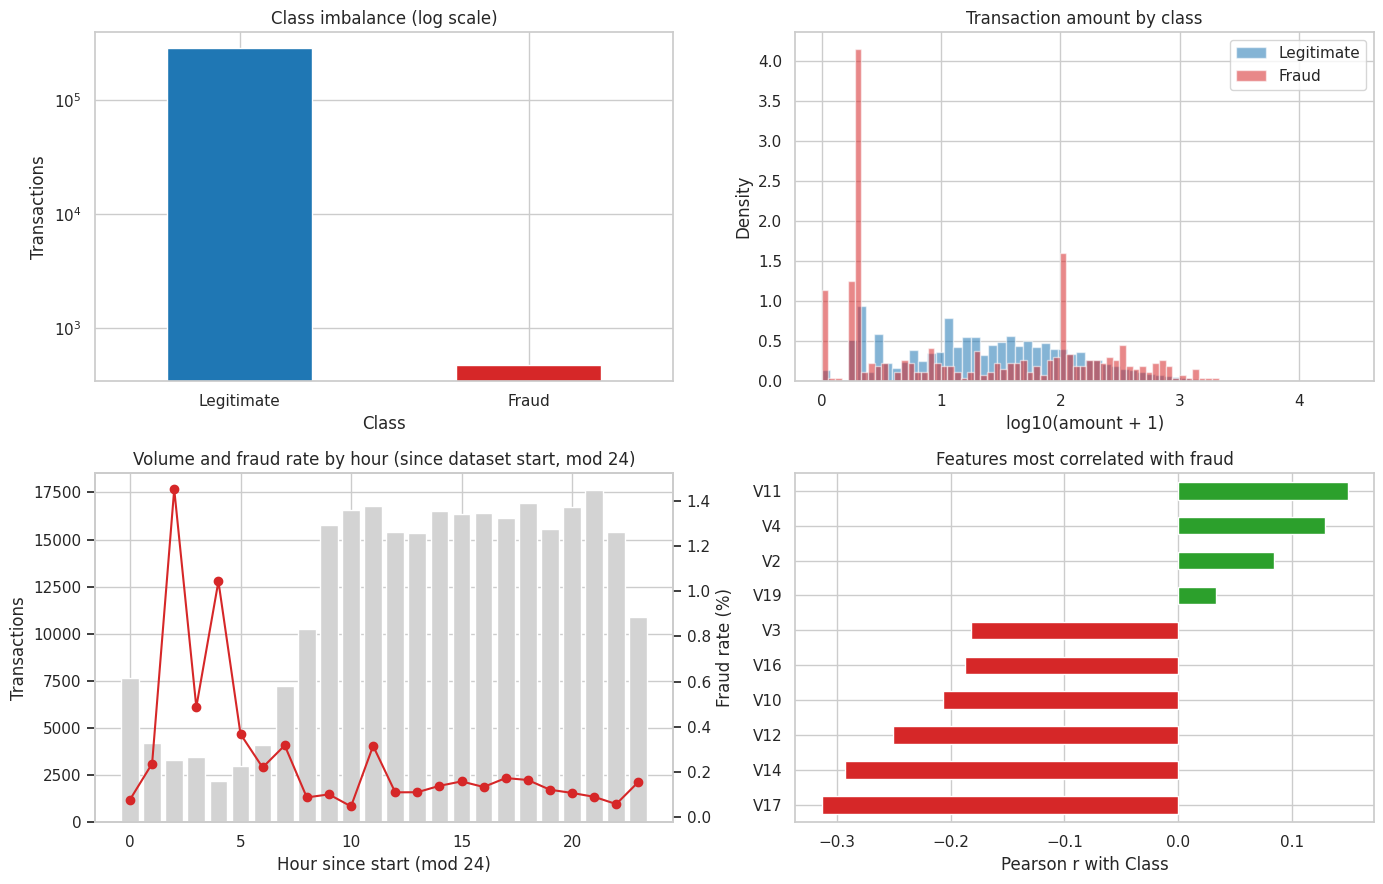

Fraud rate peaks at hour 2 (counted from the first transaction, mod 24; both days pooled): 1.45% vs an overall 0.167%. The four quietest hours are [2, 3, 4, 5].


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
cls = df["Class"].map({0: "Legitimate", 1: "Fraud"})
cls.value_counts().plot.bar(ax=axes[0, 0], color=["tab:blue", "tab:red"], rot=0, logy=True)
axes[0, 0].set(title="Class imbalance (log scale)", ylabel="Transactions")
for c, color in [(0, "tab:blue"), (1, "tab:red")]:
    axes[0, 1].hist(np.log10(df.loc[df.Class == c, "Amount"] + 1), bins=60, density=True, alpha=0.55, color=color,
                    label=["Legitimate", "Fraud"][c])
axes[0, 1].set(title="Transaction amount by class", xlabel="log10(amount + 1)", ylabel="Density"); axes[0, 1].legend()

hourly = df.groupby("Hour").agg(transactions=("Class", "size"), fraud_rate=("Class", "mean"))
ax2 = axes[1, 0]
ax2.bar(hourly.index, hourly.transactions, color="lightgray", label="Transactions")
ax2b = ax2.twinx(); ax2b.plot(hourly.index, hourly.fraud_rate * 100, color="tab:red", marker="o", label="Fraud rate")
ax2.set(title="Volume and fraud rate by hour (since dataset start, mod 24)", xlabel="Hour since start (mod 24)", ylabel="Transactions")
ax2b.set_ylabel("Fraud rate (%)"); ax2b.grid(False)

corr = df.drop(columns=["Class", "Hour"]).corrwith(df["Class"]).sort_values()
pd.concat([corr.head(6), corr.tail(4)]).plot.barh(ax=axes[1, 1], color=["tab:red"] * 6 + ["tab:green"] * 4)
axes[1, 1].set(title="Features most correlated with fraud", xlabel="Pearson r with Class")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_fraud_eda.png", dpi=200); plt.show()

peak = hourly.fraud_rate.idxmax()
peak = int(peak)
quiet = hourly.transactions.nsmallest(4).index.astype(int).tolist()
print(f"Fraud rate peaks at hour {peak} (counted from the first transaction, mod 24; both days pooled): "
      f"{hourly.fraud_rate.max():.2%} vs an overall {df.Class.mean():.3%}. The four quietest hours are {sorted(quiet)}.")

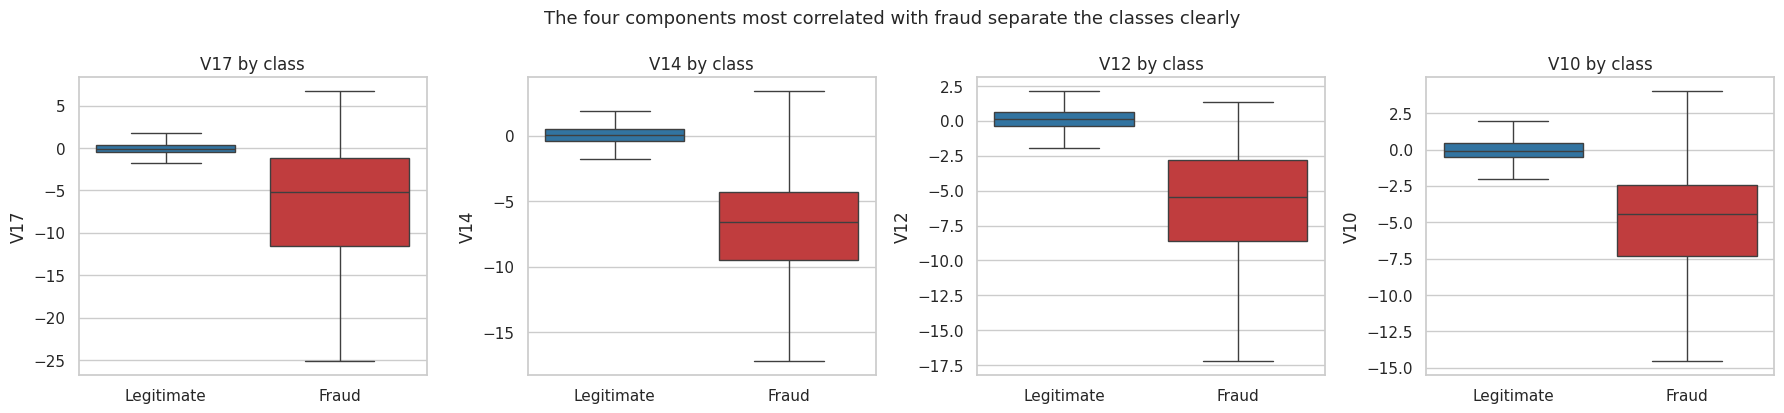

In [8]:
top_corr = df.drop(columns=["Class", "Hour", "Time"]).corrwith(df["Class"]).abs().nlargest(4).index.tolist()
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, f in zip(axes, top_corr):
    sns.boxplot(data=df, x=cls, y=f, ax=ax, hue=cls, palette={"Legitimate": "tab:blue", "Fraud": "tab:red"},
                showfliers=False, legend=False)
    ax.set(title=f"{f} by class", xlabel="")
fig.suptitle("The four components most correlated with fraud separate the classes clearly", fontsize=13)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1b_top_feature_distributions.png", dpi=200); plt.show()

### Preprocessing plan

1. **Stratified 80/20 train/test split first**, so the test set keeps the real 0.17% fraud rate and is never resampled.
2. **RobustScaler on `Amount`** (the PCA features are already centred), because amounts are heavily skewed.
   **`Time` is not used as a model feature:** it counts seconds since the recording started, which means nothing for a
   live transaction, and with a random split it could look predictive for the wrong reason.
3. **SMOTE inside the pipeline.** Synthetic frauds are generated only from the training folds of each cross-validation
   split, never from validation or test data, which would otherwise inflate the scores. `sampling_strategy=0.1` lifts
   fraud to 10% of the legitimate count rather than 50/50, which creates far fewer synthetic points and usually preserves more precision.

In [9]:
FEATURES = [c for c in df.columns if c not in ("Class", "Hour", "Time")]
X, y = df[FEATURES], df["Class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train: {len(X_train):,} ({y_train.sum()} fraud) | Test: {len(X_test):,} ({y_test.sum()} fraud)")

preprocess = ColumnTransformer([("robust", RobustScaler(), ["Amount"])], remainder="passthrough",
                               verbose_feature_names_out=False)
smote = SMOTE(sampling_strategy=0.1, random_state=SEED)

demo_X, demo_y = smote.fit_resample(preprocess.fit_transform(X_train), y_train)   # illustration only
print(f"SMOTE on the training set: fraud {y_train.sum()} -> {demo_y.sum():,}; legitimate unchanged at {(demo_y == 0).sum():,}")

Train: 226,980 (378 fraud) | Test: 56,746 (95 fraud)
SMOTE on the training set: fraud 378 -> 22,660; legitimate unchanged at 226,602


## Step 2 · Model training and optimization

Each model is a pipeline: `RobustScaler → SMOTE → classifier`. `GridSearchCV` uses **stratified 3-fold cross-validation**
and records F1, AUC-ROC, precision, recall and PR-AUC; the best setting is chosen by **F1**, with AUC-ROC reported alongside.

In [10]:
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
SCORING = {"f1": "f1", "roc_auc": "roc_auc", "precision": "precision", "recall": "recall", "pr_auc": "average_precision"}

def make_pipe(clf):
    # fresh copies of each step, so pipelines never share fitted state
    return Pipeline([("pre", clone(preprocess)), ("smote", clone(smote)), ("clf", clone(clf))])

SEARCHES = {
    "Logistic Regression": (LogisticRegression(max_iter=3000), {"clf__C": [0.00001, 0.0001, 0.001, 0.01, 0.1, 1]}),
    "XGBoost": (XGBClassifier(n_estimators=300, tree_method="hist", eval_metric="logloss", n_jobs=1, random_state=SEED),
                {"clf__max_depth": [4, 6], "clf__learning_rate": [0.05, 0.1]}),
    "Random Forest": (RandomForestClassifier(n_estimators=100, max_samples=0.3, n_jobs=1, random_state=SEED),
                      {"clf__max_depth": [None, 12], "clf__min_samples_leaf": [1, 3]}),
}

searches, cv_rows = {}, []
for name, (clf, grid) in SEARCHES.items():
    t0 = time.time()
    gs = GridSearchCV(make_pipe(clf), grid, scoring=SCORING, refit="f1", cv=CV, n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    i, r = gs.best_index_, gs.cv_results_
    cv_rows.append({"model": name, "best params": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
                    **{f"CV {m}": f"{r[f'mean_test_{m}'][i]:.4f} ± {r[f'std_test_{m}'][i]:.4f}" for m in SCORING},
                    "search time (s)": round(time.time() - t0)})
    print(f"{name}: done in {time.time() - t0:.0f}s")

cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table

Logistic Regression: done in 14s
XGBoost: done in 97s
Random Forest: done in 613s


,best params,CV f1,CV roc_auc,CV precision,CV recall,CV pr_auc,search time (s)
model,,,,,,,
Logistic Regression,{'C': 0.0001},0.7711 ± 0.0053,0.9844 ± 0.0063,0.7252 ± 0.0182,0.8254 ± 0.0361,0.7397 ± 0.0201,14
XGBoost,"{'learning_rate': 0.1, 'max_depth': 6}",0.8492 ± 0.0154,0.9778 ± 0.0041,0.8849 ± 0.0472,0.8201 ± 0.0441,0.8496 ± 0.0216,97
Random Forest,"{'max_depth': None, 'min_samples_leaf': 1}",0.8302 ± 0.0212,0.9771 ± 0.0064,0.8203 ± 0.0533,0.8439 ± 0.0320,0.8327 ± 0.0123,613


### Voting ensemble

The two strongest models by cross-validated F1 are combined with **soft voting** (averaging their fraud probabilities),
and the version with all three models is checked too. Both candidates go through the same stratified folds, with SMOTE
inside, and are compared on their pooled out-of-fold predictions; those predictions are reused later to pick thresholds.

In [12]:
ranked = cv_table.assign(f1=[searches[m].best_score_ for m in cv_table.index]).sort_values("f1", ascending=False).index.tolist()
best_clf = {name: searches[name].best_estimator_.named_steps["clf"] for name in searches}

def voting(names):
    return make_pipe(VotingClassifier([(n, best_clf[n]) for n in names], voting="soft", n_jobs=1))

candidates = {" + ".join(ranked[:2]): ranked[:2], "All three": ranked}

def pooled_cv(p):
    pred = (p >= 0.5).astype(int)
    return {"CV f1": f1_score(y_train, pred), "CV roc_auc": roc_auc_score(y_train, p),
            "CV precision": precision_score(y_train, pred), "CV recall": recall_score(y_train, pred),
            "CV pr_auc": average_precision_score(y_train, p)}

OOF, ens_rows = {}, []
for label, names in candidates.items():
    OOF[label] = cross_val_predict(voting(names), X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
    ens_rows.append({"ensemble": label, **pooled_cv(OOF[label])})
ens_table = pd.DataFrame(ens_rows).set_index("ensemble")
ENSEMBLE_LABEL = ens_table["CV f1"].idxmax()
ensemble = voting(candidates[ENSEMBLE_LABEL]).fit(X_train, y_train)
xgb_std = searches["XGBoost"].cv_results_["std_test_f1"][searches["XGBoost"].best_index_]
print(f"Selected ensemble: {ENSEMBLE_LABEL} (highest CV F1, pooled out-of-fold predictions).")
print(f"Its CV F1 gain over XGBoost alone is {ens_table.loc[ENSEMBLE_LABEL, 'CV f1'] - searches['XGBoost'].best_score_:+.4f}, "
      f"compared with a fold-to-fold standard deviation of {xgb_std:.4f}.")
ens_table

Selected ensemble: XGBoost + Random Forest (highest CV F1, pooled out-of-fold predictions).
Its CV F1 gain over XGBoost alone is +0.0048, compared with a fold-to-fold standard deviation of 0.0154.


,CV f1,CV roc_auc,CV precision,CV recall,CV pr_auc
ensemble,,,,,
XGBoost + Random Forest,0.8540,0.9816,0.8817,0.8280,0.8426
All three,0.8400,0.9856,0.8468,0.8333,0.8434


### Feature importance: what predicts fraud?

Four views: random forest impurity importance, XGBoost gain, the logistic regression coefficients scaled by each
feature's standard deviation, and
**permutation importance of the final ensemble on the test set** (how much PR-AUC drops when a feature is shuffled).

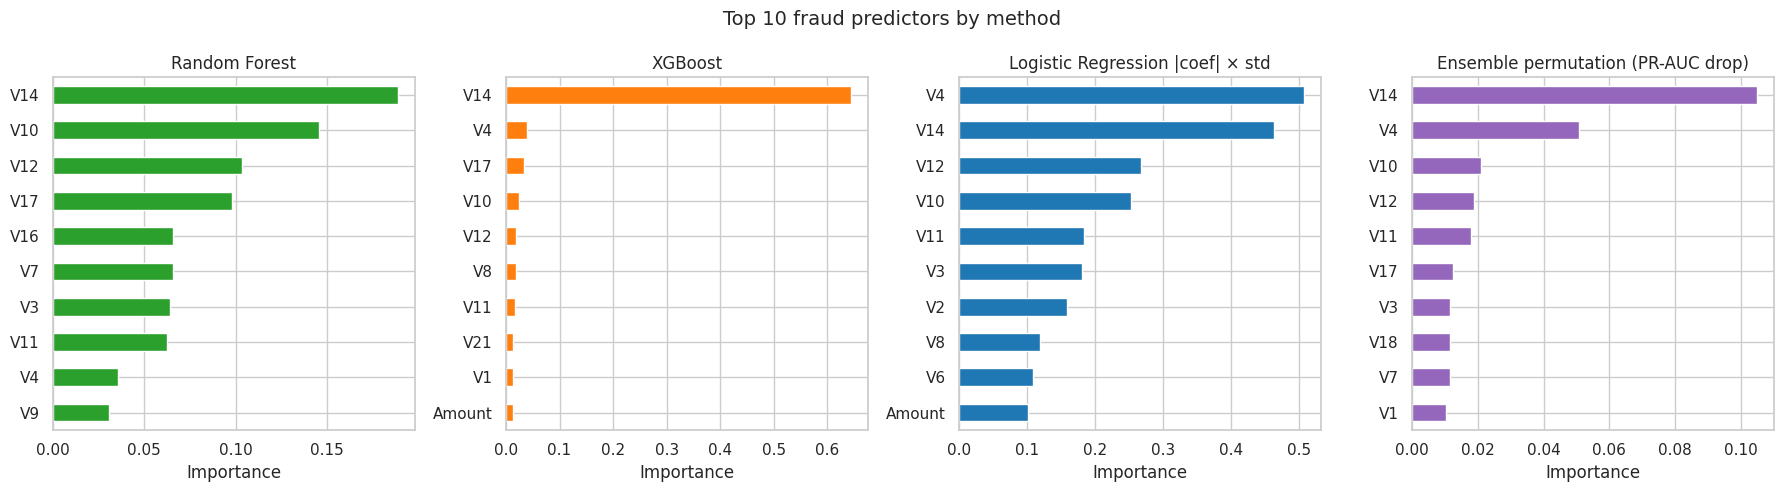

Consensus top 8 (mean rank across the four methods): V14, V10, V4, V12, V11, V17, V3, Amount


,Random Forest,XGBoost,Logistic Regression |coef| × std,Ensemble permutation (PR-AUC drop),mean rank
V14,0.1887,0.6434,0.4635,0.1048,1.2500
V10,0.1459,0.0245,0.2528,0.0209,3.2500
V4,0.0354,0.0385,0.5068,0.0507,3.5000
V12,0.1037,0.0196,0.2676,0.0188,3.7500
V11,0.0623,0.0170,0.1844,0.0179,6.2500
V17,0.0982,0.0344,0.0566,0.0125,7.0000
V3,0.0640,0.0103,0.1806,0.0116,9.0000
Amount,0.0080,0.0124,0.1011,0.0102,12.0000
V1,0.0093,0.0131,0.0393,0.0104,12.2500
V7,0.0655,0.0117,0.0120,0.0114,12.5000


In [13]:
names_out = preprocess.fit(X_train).get_feature_names_out()
imp = pd.DataFrame(index=names_out)
imp["Random Forest"] = searches["Random Forest"].best_estimator_.named_steps["clf"].feature_importances_
imp["XGBoost"] = searches["XGBoost"].best_estimator_.named_steps["clf"].feature_importances_
feat_std = preprocess.transform(X_train).std(axis=0)          # coefficients are scaled by feature spread to be comparable
imp["Logistic Regression |coef| × std"] = np.abs(searches["Logistic Regression"].best_estimator_.named_steps["clf"].coef_[0]) * feat_std

perm = permutation_importance(ensemble, X_test, y_test, scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=-1)
imp["Ensemble permutation (PR-AUC drop)"] = pd.Series(perm.importances_mean, index=X_test.columns).reindex(names_out).values

ranks = imp.rank(ascending=False)
imp["mean rank"] = ranks.mean(axis=1)
imp = imp.sort_values("mean rank")

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col, color in zip(axes, imp.columns[:4], ["tab:green", "tab:orange", "tab:blue", "tab:purple"]):
    imp[col].sort_values().tail(10).plot.barh(ax=ax, color=color)
    ax.set(title=col, xlabel="Importance")
fig.suptitle("Top 10 fraud predictors by method", fontsize=14)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig2_feature_importance.png", dpi=200); plt.show()
TOP_FEATURES = imp.index[:8].tolist()
print("Consensus top 8 (mean rank across the four methods):", ", ".join(TOP_FEATURES))
imp.head(10)

## Step 3 · Evaluation, dashboard and threat intelligence

### Test-set performance of all models

All metrics are on the untouched test set (real 0.17% fraud rate) at the default 0.5 probability threshold.
PR-AUC is the most informative single number here, because AUC-ROC looks flattering when 99.8% of cases are negative.

In [14]:
models = {name: searches[name].best_estimator_ for name in ["Logistic Regression", "Random Forest", "XGBoost"]}
models[f"Ensemble ({ENSEMBLE_LABEL})"] = ensemble
proba = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}

def metrics(y_true, p, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred), "AUC-ROC": roc_auc_score(y_true, p), "PR-AUC": average_precision_score(y_true, p),
            "TP": tp, "FP": fp, "FN": fn}

test_table = pd.DataFrame({n: metrics(y_test, p) for n, p in proba.items()}).T
test_table

,precision,recall,F1,AUC-ROC,PR-AUC,TP,FP,FN
Logistic Regression,0.7184,0.7789,0.7475,0.9683,0.6723,74.0000,29.0000,21.0000
Random Forest,0.8706,0.7789,0.8222,0.9719,0.8236,74.0000,11.0000,21.0000
XGBoost,0.8261,0.8000,0.8128,0.9718,0.8201,76.0000,16.0000,19.0000
Ensemble (XGBoost + Random Forest),0.9048,0.8000,0.8492,0.9824,0.8287,76.0000,8.0000,19.0000


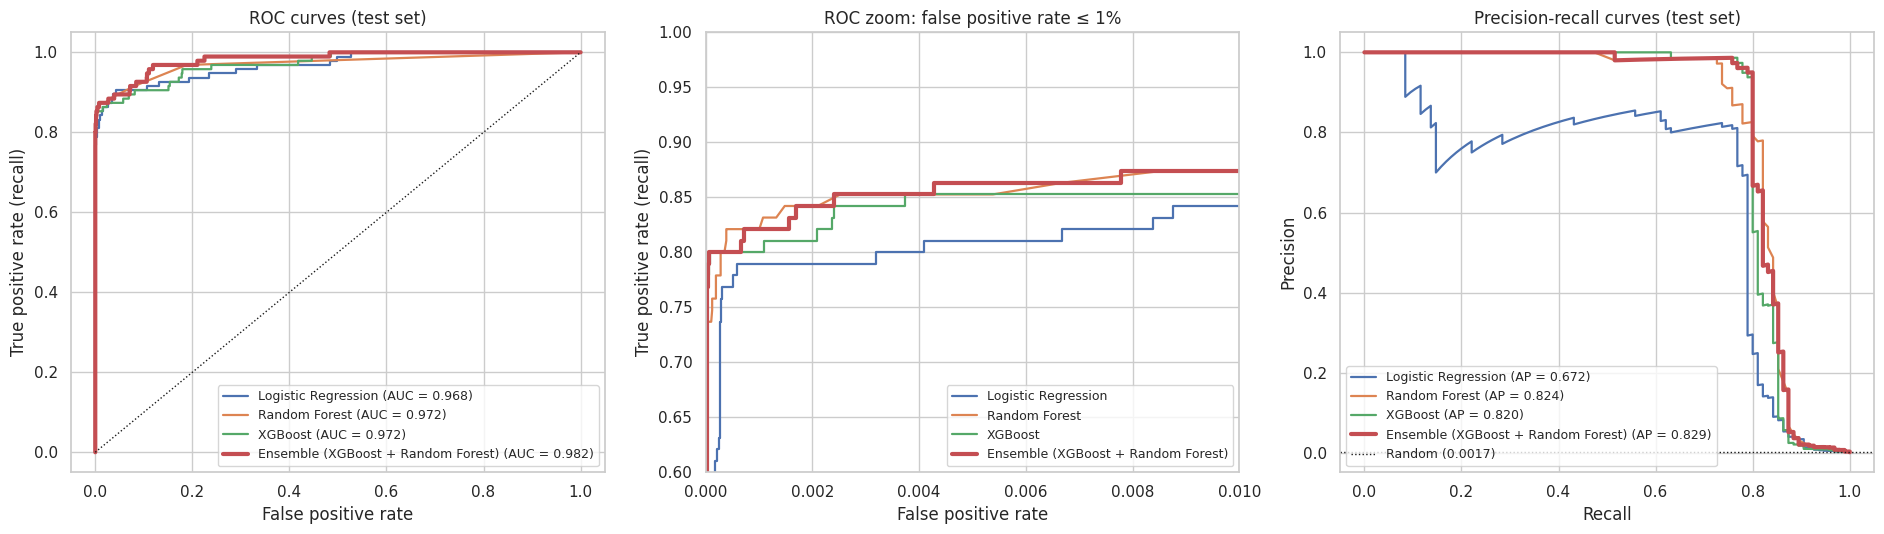

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for name, p in proba.items():
    f_, t_, _ = roc_curve(y_test, p); pr, rc, _ = precision_recall_curve(y_test, p)
    lw = 3 if name.startswith("Ensemble") else 1.6
    axes[0].plot(f_, t_, lw=lw, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
    axes[1].plot(f_, t_, lw=lw, label=name)
    axes[2].plot(rc, pr, lw=lw, label=f"{name} (AP = {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set(title="ROC curves (test set)", xlabel="False positive rate", ylabel="True positive rate (recall)")
axes[0].legend(loc="lower right", fontsize=9)
axes[1].set(xlim=(0, 0.01), ylim=(0.6, 1.0), title="ROC zoom: false positive rate ≤ 1%",
            xlabel="False positive rate", ylabel="True positive rate (recall)")
axes[1].legend(loc="lower right", fontsize=9)
axes[2].axhline(y_test.mean(), color="k", ls=":", lw=1, label=f"Random ({y_test.mean():.4f})")
axes[2].set(title="Precision-recall curves (test set)", xlabel="Recall", ylabel="Precision")
axes[2].legend(loc="lower left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig3_roc_pr_curves.png", dpi=200); plt.show()

### Recommended detection thresholds

Thresholds are chosen on **out-of-fold predictions from the training set** (3-fold, SMOTE inside each fold), never on
the test set, and then checked on the test set. The operating points match different business appetites; the default
0.5 is shown for reference.

In [16]:
oof = OOF[ENSEMBLE_LABEL]
pr, rc, th = precision_recall_curve(y_train, oof)
pr, rc = pr[:-1], rc[:-1]
f1s = 2 * pr * rc / np.clip(pr + rc, 1e-9, None)
OPERATING_POINTS = {
    "Balanced (max F1 in training)": th[np.argmax(f1s)],
    "High recall (≥ 90% recall in training)": th[np.where(rc >= 0.90)[0].max()],
    "Alert budget (≤ 100 alerts per 100k in training)": np.quantile(oof, 1 - 0.001),
    "Reference: default 0.5": 0.5,
}
p_ens = proba[f"Ensemble ({ENSEMBLE_LABEL})"]
rows = []
for label, thr in OPERATING_POINTS.items():
    m = metrics(y_test, p_ens, thr)
    alerts = int(m["TP"] + m["FP"])
    rows.append({"operating point": label, "threshold": thr, "test precision": m["precision"], "test recall": m["recall"],
                 "test F1": m["F1"], "frauds caught": f"{int(m['TP'])} of {int(y_test.sum())}",
                 "alerts per 100k transactions": alerts / len(y_test) * 1e5})
thr_table = pd.DataFrame(rows).set_index("operating point")
THRESHOLD = OPERATING_POINTS["Balanced (max F1 in training)"]
thr_table

,threshold,test precision,test recall,test F1,frauds caught,alerts per 100k transactions
operating point,,,,,,
Balanced (max F1 in training),0.7737,0.9859,0.7368,0.8434,70 of 95,125.1190
High recall (≥ 90% recall in training),0.0257,0.0847,0.8737,0.1544,83 of 95,1726.9940
Alert budget (≤ 100 alerts per 100k in training),0.9750,0.9828,0.6000,0.7451,57 of 95,102.2098
Reference: default 0.5,0.5000,0.9048,0.8000,0.8492,76 of 95,148.0281


In [17]:
bal, ref = thr_table.iloc[0], thr_table.loc["Reference: default 0.5"]
display(Markdown(f"""
**A calibration caveat.** The out-of-fold scores come from models trained on two-thirds of the training data, while the
deployed ensemble is trained on all of it, so its probabilities are distributed differently. On the test set the balanced
threshold ({THRESHOLD:.3f}) caught {bal['frauds caught']} frauds with F1 {bal['test F1']:.3f}, while the default 0.5 caught
{ref['frauds caught']} with F1 {ref['test F1']:.3f}. The test set is only used here to check, not to choose; in production the
threshold should be re-calibrated on a recent, labelled validation window and reviewed with the fraud team.
"""))


**A calibration caveat.** The out-of-fold scores come from models trained on two-thirds of the training data, while the
deployed ensemble is trained on all of it, so its probabilities are distributed differently. On the test set the balanced
threshold (0.774) caught 70 of 95 frauds with F1 0.843, while the default 0.5 caught
76 of 95 with F1 0.849. The test set is only used here to check, not to choose; in production the
threshold should be re-calibrated on a recent, labelled validation window and reviewed with the fraud team.


### Fraud detection dashboard

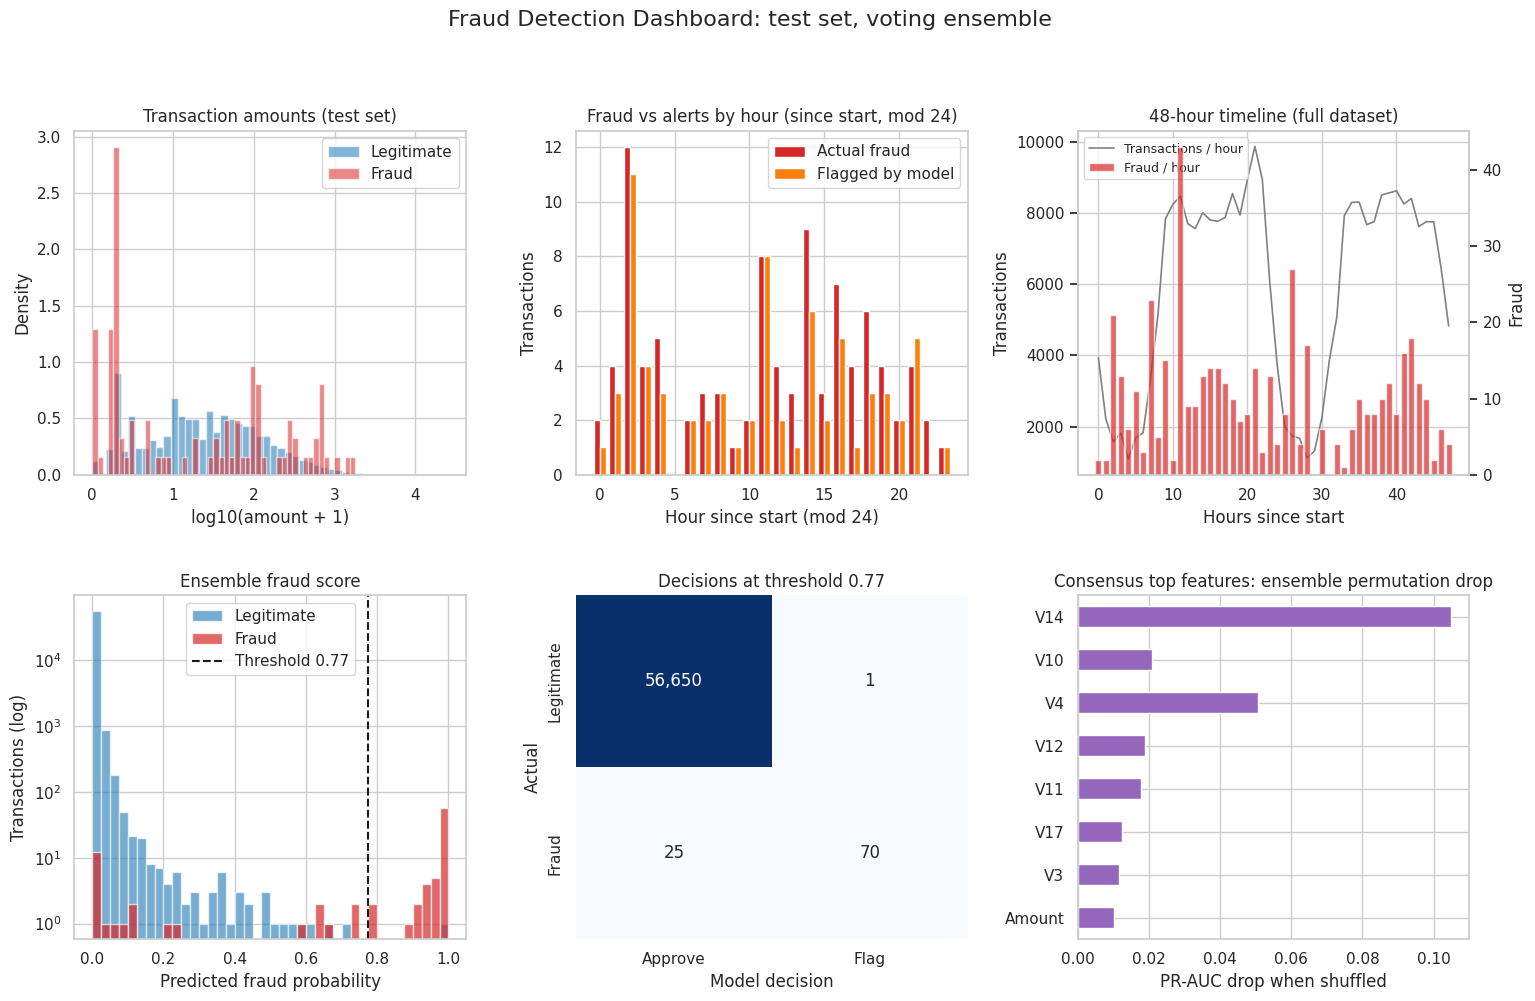

In [18]:
pred = (p_ens >= THRESHOLD).astype(int)
test_view = X_test.assign(Class=y_test.values, score=p_ens, flagged=pred, Hour=df.loc[X_test.index, "Hour"].values)
fig = plt.figure(figsize=(18, 10.5))
gsp = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.28)

ax = fig.add_subplot(gsp[0, 0])
for label, mask, color in [("Legitimate", test_view.Class == 0, "tab:blue"), ("Fraud", test_view.Class == 1, "tab:red")]:
    ax.hist(np.log10(test_view.loc[mask, "Amount"] + 1), bins=50, density=True, alpha=0.55, color=color, label=label)
ax.set(title="Transaction amounts (test set)", xlabel="log10(amount + 1)", ylabel="Density"); ax.legend()

ax = fig.add_subplot(gsp[0, 1])
hr = test_view.groupby("Hour").agg(fraud=("Class", "sum"), flagged=("flagged", "sum"))
ax.bar(hr.index - 0.2, hr.fraud, width=0.4, color="tab:red", label="Actual fraud")
ax.bar(hr.index + 0.2, hr.flagged, width=0.4, color="tab:orange", label="Flagged by model")
ax.set(title="Fraud vs alerts by hour (since start, mod 24)", xlabel="Hour since start (mod 24)", ylabel="Transactions"); ax.legend()

ax = fig.add_subplot(gsp[0, 2])
tl = df.assign(hour_index=df["Time"] // 3600).groupby("hour_index").agg(transactions=("Class", "size"), fraud=("Class", "sum"))
ax.plot(tl.index, tl.transactions, color="gray", lw=1.2, label="Transactions / hour")
axb = ax.twinx(); axb.bar(tl.index, tl.fraud, color="tab:red", alpha=0.7, label="Fraud / hour"); axb.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = axb.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)
ax.set(title="48-hour timeline (full dataset)", xlabel="Hours since start", ylabel="Transactions"); axb.set_ylabel("Fraud")

ax = fig.add_subplot(gsp[1, 0])
bins = np.linspace(0, 1, 41)
ax.hist(test_view.loc[test_view.Class == 0, "score"], bins=bins, color="tab:blue", alpha=0.6, label="Legitimate", log=True)
ax.hist(test_view.loc[test_view.Class == 1, "score"], bins=bins, color="tab:red", alpha=0.7, label="Fraud", log=True)
ax.axvline(THRESHOLD, color="k", ls="--", label=f"Threshold {THRESHOLD:.2f}")
ax.set(title="Ensemble fraud score", xlabel="Predicted fraud probability", ylabel="Transactions (log)"); ax.legend()

ax = fig.add_subplot(gsp[1, 1])
cm = confusion_matrix(test_view.Class, test_view.flagged)
sns.heatmap(cm, annot=np.array([[f"{v:,}" for v in r] for r in cm]), fmt="", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Approve", "Flag"], yticklabels=["Legitimate", "Fraud"])
ax.set(title=f"Decisions at threshold {THRESHOLD:.2f}", xlabel="Model decision", ylabel="Actual")

ax = fig.add_subplot(gsp[1, 2])
imp["Ensemble permutation (PR-AUC drop)"].head(8)[::-1].plot.barh(ax=ax, color="tab:purple")
ax.set(title="Consensus top features: ensemble permutation drop", xlabel="PR-AUC drop when shuffled")
fig.suptitle("Fraud Detection Dashboard: test set, voting ensemble", fontsize=16, y=0.995)
fig.savefig(FIG_DIR / "fig4_dashboard.png", dpi=200, bbox_inches="tight"); plt.show()

### False positives and false negatives

What do the model's mistakes look like? The table compares the four outcome groups at the balanced threshold.

In [19]:
outcome = np.select([(test_view.Class == 1) & (test_view.flagged == 1), (test_view.Class == 1) & (test_view.flagged == 0),
                     (test_view.Class == 0) & (test_view.flagged == 1)], ["True positive", "False negative", "False positive"],
                    "True negative")
test_view["outcome"] = outcome
cols = ["Amount", "score"] + TOP_FEATURES[:4]
err = test_view.groupby("outcome")[cols].median().reindex(["True positive", "False negative", "False positive", "True negative"])
err.insert(0, "count", test_view["outcome"].value_counts())
err

,count,Amount,score,V14,V10,V4,V12
outcome,,,,,,,
True positive,70,34.2950,0.9949,-7.2060,-5.1630,4.9049,-6.1492
False negative,25,2.2200,0.0407,-0.9946,-0.2837,2.3302,-0.3388
False positive,1,109.9000,0.9844,-7.1096,-5.6220,3.8028,-7.1045
True negative,56650,21.6000,0.0000,0.0572,-0.0905,-0.0253,0.1446


In [20]:
fn, fp_ = test_view[test_view.outcome == "False negative"], test_view[test_view.outcome == "False positive"]
tp_ = test_view[test_view.outcome == "True positive"]
tn_ = test_view[test_view.outcome == "True negative"]
plural = lambda n, word: f"{n} {word}{'' if n == 1 else 's'}"
if len(fp_) == 0:
    fp_line = "no false alarms at all."
else:
    hard = fp_.score.median() > THRESHOLD + 0.1
    one = len(fp_) == 1
    score_txt = f"a score of {fp_.score.iloc[0]:.3f}" if one else f"a median score of {fp_.score.median():.3f}"
    if hard:
        why = ("it scores far above the threshold and resembles fraud on the top features, so it is a hard case rather than a borderline one"
               if one else "they score far above the threshold and resemble fraud on the top features, so they are hard cases rather than borderline ones")
        action = "an analyst review, not a hard decline, is the right response"
    else:
        why = "it sits close to the threshold" if one else "they sit close to the threshold"
        action = "a step-up check (for example a one-time passcode) is cheaper than a hard decline"
    fp_line = f"with {score_txt}: {why}; {action}."
display(Markdown(f"""
**Reading the errors**

- **{plural(len(fn), 'missed fraud')} (false negatives)** have a median fraud score of **{fn.score.median():.3f}**, against
  {tp_.score.median():.3f} for caught frauds. On the top predictor, `{TOP_FEATURES[0]}`, their median is
  {fn[TOP_FEATURES[0]].median():.2f}, much closer to legitimate traffic ({tn_[TOP_FEATURES[0]].median():.2f})
  than to caught fraud ({tp_[TOP_FEATURES[0]].median():.2f}). These frauds look ordinary in the features the models rely on.
- Missed frauds have a median amount of **€{fn.Amount.median():.2f}**, against €{tp_.Amount.median():.2f} for caught frauds.
- **{plural(len(fp_), 'false alarm')}** out of {int((test_view.Class == 0).sum()):,} legitimate test transactions
  ({len(fp_) / (test_view.Class == 0).sum():.3%}), {fp_line}
"""))


**Reading the errors**

- **25 missed frauds (false negatives)** have a median fraud score of **0.041**, against
  0.995 for caught frauds. On the top predictor, `V14`, their median is
  -0.99, much closer to legitimate traffic (0.06)
  than to caught fraud (-7.21). These frauds look ordinary in the features the models rely on.
- Missed frauds have a median amount of **€2.22**, against €34.30 for caught frauds.
- **1 false alarm** out of 56,651 legitimate test transactions
  (0.002%), with a score of 0.984: it scores far above the threshold and resembles fraud on the top features, so it is a hard case rather than a borderline one; an analyst review, not a hard decline, is the right response.


### Threat intelligence report

The report below is generated from this run's results, so every number matches the outputs above.

In [21]:
ens_m = test_table.loc[f"Ensemble ({ENSEMBLE_LABEL})"]
best_single = test_table.drop(index=f"Ensemble ({ENSEMBLE_LABEL})")["PR-AUC"].idxmax()
fr, lg = df[df.Class == 1], df[df.Class == 0]
bal, hp, bud, ref = (thr_table.iloc[i] for i in range(4))
display(Markdown(f"""
#### Fraud Threat Intelligence Report: card transaction monitoring

**1. Threat picture.** {len(fr)} of {len(df):,} transactions ({df.Class.mean():.3%}) were fraud. The *median* fraud is small,
€{fr.Amount.median():.2f} against €{lg.Amount.median():.2f} for legitimate payments, and {(fr.Amount <= 1).mean():.0%} of frauds
are €1 or less, a pattern often associated with card testing (small trial charges), although the anonymised data cannot
confirm intent. A tail of larger frauds still pushes the fraud *mean* (€{fr.Amount.mean():.2f}) above the legitimate mean
(€{lg.Amount.mean():.2f}). The fraud *rate* peaks at hour {peak} counted from the first transaction ({hourly.fraud_rate.max():.2%},
both days pooled), one of the lowest-volume hours of the cycle.

**2. Top fraud indicators** (ranked by mean position across four importance methods): {", ".join(f"`{f}`" for f in TOP_FEATURES[:6])}.
They are anonymised PCA components, so the bank's data team should map them back to raw behaviours
(merchant category, geography, device, velocity) to turn them into named rules.

**3. Detection capability.** The {ENSEMBLE_LABEL} soft-voting ensemble reached precision {ens_m['precision']:.3f}, recall
{ens_m['recall']:.3f}, F1 {ens_m['F1']:.3f}, AUC-ROC {ens_m['AUC-ROC']:.3f} and PR-AUC {ens_m['PR-AUC']:.3f} on unseen data at
threshold 0.5. The best single model by PR-AUC was {best_single} ({test_table.loc[best_single, 'PR-AUC']:.3f}).

**4. Recommended thresholds** (chosen on training folds only, checked on the test set):

| Appetite | Threshold | Fraud caught | Precision | Alerts / 100k |
|---|---|---|---|---|
| Balanced, *recommended starting point* | {bal['threshold']:.3f} | {bal['frauds caught']} | {bal['test precision']:.2f} | {bal['alerts per 100k transactions']:,.0f} |
| High recall (fraud-loss averse) | {hp['threshold']:.3f} | {hp['frauds caught']} | {hp['test precision']:.2f} | {hp['alerts per 100k transactions']:,.0f} |
| Alert budget (analyst-capacity limited) | {bud['threshold']:.3f} | {bud['frauds caught']} | {bud['test precision']:.2f} | {bud['alerts per 100k transactions']:,.0f} |

Because of the calibration gap noted above, these are starting points: re-calibrate them on a recent labelled window.

**5. Actions.** (a) Score every authorisation in real time and use the balanced threshold for automatic holds.
(b) Route scores in the band just below the threshold to step-up authentication rather than decline.
(c) Missed frauds look legitimate on the top components, so add behavioural context the dataset lacks:
per-card velocity, device and geolocation changes. (d) Retrain monthly and monitor the alert rate for drift.
"""))


#### Fraud Threat Intelligence Report: card transaction monitoring

**1. Threat picture.** 473 of 283,726 transactions (0.167%) were fraud. The *median* fraud is small,
€9.82 against €22.00 for legitimate payments, and 36% of frauds
are €1 or less, a pattern often associated with card testing (small trial charges), although the anonymised data cannot
confirm intent. A tail of larger frauds still pushes the fraud *mean* (€123.87) above the legitimate mean
(€88.41). The fraud *rate* peaks at hour 2 counted from the first transaction (1.45%,
both days pooled), one of the lowest-volume hours of the cycle.

**2. Top fraud indicators** (ranked by mean position across four importance methods): `V14`, `V10`, `V4`, `V12`, `V11`, `V17`.
They are anonymised PCA components, so the bank's data team should map them back to raw behaviours
(merchant category, geography, device, velocity) to turn them into named rules.

**3. Detection capability.** The XGBoost + Random Forest soft-voting ensemble reached precision 0.905, recall
0.800, F1 0.849, AUC-ROC 0.982 and PR-AUC 0.829 on unseen data at
threshold 0.5. The best single model by PR-AUC was Random Forest (0.824).

**4. Recommended thresholds** (chosen on training folds only, checked on the test set):

| Appetite | Threshold | Fraud caught | Precision | Alerts / 100k |
|---|---|---|---|---|
| Balanced, *recommended starting point* | 0.774 | 70 of 95 | 0.99 | 125 |
| High recall (fraud-loss averse) | 0.026 | 83 of 95 | 0.08 | 1,727 |
| Alert budget (analyst-capacity limited) | 0.975 | 57 of 95 | 0.98 | 102 |

Because of the calibration gap noted above, these are starting points: re-calibrate them on a recent labelled window.

**5. Actions.** (a) Score every authorisation in real time and use the balanced threshold for automatic holds.
(b) Route scores in the band just below the threshold to step-up authentication rather than decline.
(c) Missed frauds look legitimate on the top components, so add behavioural context the dataset lacks:
per-card velocity, device and geolocation changes. (d) Retrain monthly and monitor the alert rate for drift.


### Real-time scoring simulation with an uncertainty band

Transactions from the held-out test set are scored one at a time, grouped into realistic scenarios: a card-testing burst
(the smallest-value frauds), a high-value fraud, large legitimate purchases and routine traffic. Frauds are deliberately
over-represented for illustration. The uncertainty band comes from **15 ensembles refit on random halves of the training
data** (half-sample subsampling); the band spans the 2.5th–97.5th percentile of their scores, which with 15 models is close to
their minimum and maximum, so treat it as a rough range. The deployed model, trained on all the data, can score slightly
outside it. Decisions use the band, not just the point score: **block** if the whole band is above the threshold,
**approve** if it is entirely below, and **review** otherwise.

In [22]:
B = 15
rng = np.random.default_rng(SEED)
halves = [rng.choice(len(X_train), size=len(X_train) // 2, replace=False) for _ in range(B)]
t0 = time.time()
boot_models = Parallel(n_jobs=-1)(delayed(lambda idx: voting(candidates[ENSEMBLE_LABEL]).fit(X_train.iloc[idx], y_train.iloc[idx]))(idx)
                                  for idx in halves)
print(f"Fitted {B} half-sample ensembles in {time.time() - t0:.0f}s")

frauds_te, legit_te = X_test[y_test == 1], X_test[y_test == 0]
card_testing = frauds_te.nsmallest(3, "Amount")
high_value = frauds_te.drop(card_testing.index).nlargest(1, "Amount")
big_legit = legit_te.nlargest(2, "Amount")
routine = pd.concat([frauds_te.drop(card_testing.index.union(high_value.index)).sample(2, random_state=SEED),
                     legit_te.drop(big_legit.index).sample(10, random_state=SEED)]).sample(frac=1, random_state=SEED)
stream = pd.concat([card_testing, high_value, big_legit, routine])
scenario = (["Card-testing burst"] * len(card_testing) + ["High-value fraud"] * len(high_value)
            + ["Large legitimate purchase"] * len(big_legit) + ["Routine traffic"] * len(routine))

ensemble.predict_proba(stream.iloc[[0]]); [m.predict_proba(stream.iloc[[0]]) for m in boot_models]   # warm-up
records = []
for (tx_id, row), scen in zip(stream.iterrows(), scenario):
    x = row.to_frame().T
    t1 = time.perf_counter()
    score = ensemble.predict_proba(x)[0, 1]
    t2 = time.perf_counter()
    boot = np.array([m.predict_proba(x)[0, 1] for m in boot_models])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    decision = "BLOCK" if lo >= THRESHOLD else ("APPROVE" if hi < THRESHOLD else "REVIEW")
    t3 = time.perf_counter()
    records.append({"scenario": scen, "transaction": tx_id, "amount (€)": row["Amount"], "deployed score": score,
                    "median of 15": np.median(boot), "uncertainty band": f"[{lo:.3f}, {hi:.3f}]", "decision": decision,
                    "actual": "Fraud" if y_test.loc[tx_id] == 1 else "Legit",
                    "score (ms)": (t2 - t1) * 1000, "full decision (ms)": (t3 - t1) * 1000})
live = pd.DataFrame(records).set_index(["scenario", "transaction"])
print(f"Median latency: {live['score (ms)'].median():.1f} ms for the deployed score, "
      f"{live['full decision (ms)'].median():.1f} ms including the 15-model uncertainty band")
live

Fitted 15 half-sample ensembles in 542s
Median latency: 9.5 ms for the deployed score, 155.8 ms including the 15-model uncertainty band


amount (€)  deployed score  \
scenario                  transaction                               
Card-testing burst        202971           0.0000          0.9999   
                          156390           0.0000          0.9950   
                          154122           0.0000          1.0000   
High-value fraud          6932          1809.6800          0.7885   
Large legitimate purchase 273745       25691.1600          0.4185   
                          53784        11898.0900          0.0100   
Routine traffic           224227         118.8500          0.0000   
                          78537           22.8200          0.0000   
                          534              0.0000          0.9799   
                          46075           39.9500          0.0000   
                          249847          80.4000          0.0000   
                          221335          45.0000          0.0000   
                          106646         318.1100          0.9850   
                          129038          37.0000          0.0000   
                          224658          29.0000          0.0102   
                          119923          17.9900          0.0000   
                          265118           9.9900          0.0000   
                          241249          66.9800          0.0050   

                                       median of 15 uncertainty band decision  \
scenario                  transaction                                           
Card-testing burst        202971             0.9896   [0.945, 0.995]    BLOCK   
                          156390             0.9900   [0.977, 0.998]    BLOCK   
                          154122             0.9950   [0.982, 1.000]    BLOCK   
High-value fraud          6932               0.7576   [0.325, 0.819]   REVIEW   
Large legitimate purchase 273745             0.4856   [0.223, 0.732]  APPROVE   
                          53784              0.0150   [0.002, 0.030]  APPROVE   
Routine traffic           224227             0.0000   [0.000, 0.003]  APPROVE   
                          78537              0.0000   [0.000, 0.005]  APPROVE   
                          534                0.9650   [0.946, 0.981]    BLOCK   
                          46075              0.0000   [0.000, 0.003]  APPROVE   
                          249847             0.0000   [0.000, 0.003]  APPROVE   
                          221335             0.0000   [0.000, 0.005]  APPROVE   
                          106646             0.9900   [0.975, 0.998]    BLOCK   
                          129038             0.0000   [0.000, 0.005]  APPROVE   
                          224658             0.0053   [0.000, 0.018]  APPROVE   
                          119923             0.0000   [0.000, 0.000]  APPROVE   
                          265118             0.0000   [0.000, 0.000]  APPROVE   
                          241249             0.0050   [0.000, 0.010]  APPROVE   

                                      actual  score (ms)  full decision (ms)  
scenario                  transaction                                         
Card-testing burst        202971       Fraud      9.2013            165.8154  
                          156390       Fraud      9.3125            152.8999  
                          154122       Fraud     10.5951            178.3015  
High-value fraud          6932         Fraud      9.6496            156.1829  
Large legitimate purchase 273745       Legit      9.8911            152.5569  
                          53784        Legit      9.3215            153.7425  
Routine traffic           224227       Legit      9.0749            155.3322  
                          78537        Legit      9.3567            156.5973  
                          534          Fraud      9.2166            155.2024  
                          46075        Legit      9.3660            175.6535  
                          249847       Legit      9.5984            153.3497  
          

## Findings

In [23]:
lr_m, rf_m, xgb_m = (test_table.loc[n] for n in ["Logistic Regression", "Random Forest", "XGBoost"])
best_fp_name = "XGBoost" if xgb_m["FP"] <= rf_m["FP"] else "Random Forest"
single_fp = int(test_table.loc[best_fp_name, "FP"])
second = imp["Ensemble permutation (PR-AUC drop)"].drop(TOP_FEATURES[0]).idxmax()
n_first = int((ranks.loc[TOP_FEATURES[0]] == 1).sum())
lr_note = ("Adding Logistic Regression to the vote lowered CV F1, so it was left out." if ENSEMBLE_LABEL != "All three"
           else "Including Logistic Regression in the vote gave the best CV F1, so all three models vote.")
display(Markdown(f"""
**1. Imbalance handling worked, and SMOTE stayed inside the folds.** With {df.Class.mean():.3%} fraud, a model that predicts
"legitimate" every time is {1 - df.Class.mean():.2%} accurate and useless, so accuracy is never reported. SMOTE lifted the
training folds to a 1:10 fraud ratio, and the test set kept the real rate.

**2. Tree models beat the linear baseline; the ensemble's gain is small.** In cross-validation, XGBoost (F1
{searches['XGBoost'].best_score_:.3f}) and Random Forest ({searches['Random Forest'].best_score_:.3f}) beat Logistic Regression
({searches['Logistic Regression'].best_score_:.3f}). The {ENSEMBLE_LABEL} ensemble reached CV F1
{ens_table.loc[ENSEMBLE_LABEL, 'CV f1']:.3f}, a gain within one fold-to-fold standard deviation ({xgb_std:.3f}). On the test set it
caught {int(ens_m['TP'])} of {int(y_test.sum())} frauds with {int(ens_m['FP'])} false alarms (precision {ens_m['precision']:.3f},
F1 {ens_m['F1']:.3f}), against {int(test_table.loc[best_fp_name, 'TP'])} and {single_fp} for {best_fp_name}. With only {int(y_test.sum())} test frauds,
that difference is encouraging but not conclusive. {lr_note}

**3. AUC-ROC hides differences that PR-AUC shows.** All models scored AUC-ROC between {test_table['AUC-ROC'].min():.3f} and
{test_table['AUC-ROC'].max():.3f}, but PR-AUC ranged from {test_table['PR-AUC'].min():.3f} to {test_table['PR-AUC'].max():.3f}. With
0.17% positives, PR-AUC is the more informative summary.

**4. One component dominates.** `{TOP_FEATURES[0]}` ranked first in {'all four' if n_first == 4 else f'{n_first} of the four'} importance methods; shuffling it cut the
ensemble's PR-AUC by {imp.loc[TOP_FEATURES[0], 'Ensemble permutation (PR-AUC drop)']:.3f}, against
{imp['Ensemble permutation (PR-AUC drop)'].drop(TOP_FEATURES[0]).max():.3f} for the next largest, `{second}`.

**5. The threshold is a business decision.** Moving from the balanced threshold ({THRESHOLD:.3f}) to the high-recall one caught
{thr_table.iloc[1]['frauds caught']} instead of {thr_table.iloc[0]['frauds caught']} test frauds, but raised alerts from
{thr_table.iloc[0]['alerts per 100k transactions']:,.0f} to {thr_table.iloc[1]['alerts per 100k transactions']:,.0f} per 100,000 transactions.

**6. The misses are low-value frauds that look normal.** Missed frauds had a median amount of €{fn.Amount.median():.2f} and
near-legitimate values on the top components. That suggests the signal is weak in these features, so per-card behavioural
features (velocity, device, location) are a more promising next step than a more complex model.

**7. The phishing detective is the easier problem.** TF-IDF with logistic regression reached AUC-ROC
{roc_auc_score(ye_te, pe):.3f} on held-out emails, because phishing vocabulary ({", ".join(f'"{w}"' for w in top_phish[:3])}) differs sharply from
normal mail. Fraud has no such giveaway, which is why it needed resampling, ensembles and careful thresholds.

**Limitations.** Two days of 2013 data; PCA features that cannot be mapped to real behaviours; a random rather than
time-ordered split, which may be optimistic for deployment; thresholds affected by the calibration gap described above; and
an uncertainty band from only 15 half-sample models, which is a rough range rather than a calibrated interval.
"""))


**1. Imbalance handling worked, and SMOTE stayed inside the folds.** With 0.167% fraud, a model that predicts
"legitimate" every time is 99.83% accurate and useless, so accuracy is never reported. SMOTE lifted the
training folds to a 1:10 fraud ratio, and the test set kept the real rate.

**2. Tree models beat the linear baseline; the ensemble's gain is small.** In cross-validation, XGBoost (F1
0.849) and Random Forest (0.830) beat Logistic Regression
(0.771). The XGBoost + Random Forest ensemble reached CV F1
0.854, a gain within one fold-to-fold standard deviation (0.015). On the test set it
caught 76 of 95 frauds with 8 false alarms (precision 0.905,
F1 0.849), against 74 and 11 for Random Forest. With only 95 test frauds,
that difference is encouraging but not conclusive. Adding Logistic Regression to the vote lowered CV F1, so it was left out.

**3. AUC-ROC hides differences that PR-AUC shows.** All models scored AUC-ROC between 0.968 and
0.982, but PR-AUC ranged from 0.672 to 0.829. With
0.17% positives, PR-AUC is the more informative summary.

**4. One component dominates.** `V14` ranked first in 3 of the four importance methods; shuffling it cut the
ensemble's PR-AUC by 0.105, against
0.051 for the next largest, `V4`.

**5. The threshold is a business decision.** Moving from the balanced threshold (0.774) to the high-recall one caught
83 of 95 instead of 70 of 95 test frauds, but raised alerts from
125 to 1,727 per 100,000 transactions.

**6. The misses are low-value frauds that look normal.** Missed frauds had a median amount of €2.22 and
near-legitimate values on the top components. That suggests the signal is weak in these features, so per-card behavioural
features (velocity, device, location) are a more promising next step than a more complex model.

**7. The phishing detective is the easier problem.** TF-IDF with logistic regression reached AUC-ROC
0.998 on held-out emails, because phishing vocabulary ("click", "free", "money") differs sharply from
normal mail. Fraud has no such giveaway, which is why it needed resampling, ensembles and careful thresholds.

**Limitations.** Two days of 2013 data; PCA features that cannot be mapped to real behaviours; a random rather than
time-ordered split, which may be optimistic for deployment; thresholds affected by the calibration gap described above; and
an uncertainty band from only 15 half-sample models, which is a rough range rather than a calibrated interval.


## Reflection

In Module 1 and Module 3, I built anomaly detectors that learned only from normal traffic. This lab was the first time I
had labels, and it showed me that labels do not make the problem easy: with one fraud in every six hundred transactions,
accuracy is meaningless, and I had to keep SMOTE inside the cross-validation folds so that synthetic frauds never leaked
into validation scores. Applying SMOTE before splitting would have produced better-looking numbers and a worse model.

The other lesson repeats from earlier modules. In Module 3, my autoencoder missed attacks that looked normal in its
features; here, the frauds the ensemble missed were small payments (median €2.22) that looked close to legitimate traffic on the strongest
components, such as V14. A
stronger model will not find a signal that is not in the data. Behavioural context, such as how often a card is used or
where, would.

I want to work on detection systems where the threshold is set with the people who handle the alerts, because this lab
made the trade-off concrete: a few more frauds caught can mean many times more customers interrupted. The real-time
scoring cell, with its review band for uncertain scores, is the kind of system I would like to build: one that knows when
it is unsure and hands those cases to a person.

In [24]:
# Machine-readable summary of this run (used to generate the accompanying PDF report)
import json
SUMMARY = {
    "n_raw": int(len(raw)), "n_dupes": int(raw.duplicated().sum()), "n": int(len(df)), "n_fraud": int(df.Class.sum()),
    "fraud_rate": float(df.Class.mean()), "n_train": int(len(X_train)), "n_test": int(len(X_test)), "test_fraud": int(y_test.sum()),
    "emails": int(len(emails)), "phishing": int(emails.is_phishing.sum()), "phish_auc": float(roc_auc_score(ye_te, pe)),
    "phish_f1": float(f1_score(ye_te, (pe >= 0.5).astype(int))),
    "cv": {m: {"params": {k.replace("clf__", ""): v for k, v in searches[m].best_params_.items()},
               "f1": float(searches[m].best_score_),
               "auc": float(searches[m].cv_results_["mean_test_roc_auc"][searches[m].best_index_])} for m in searches},
    "ensemble_label": ENSEMBLE_LABEL, "ens_cv": {k: float(v) for k, v in ens_table.loc[ENSEMBLE_LABEL].items()},
    "test": {n: {k: float(v) for k, v in row.items()} for n, row in test_table.iterrows()},
    "top_features": TOP_FEATURES,
    "thresholds": {k: {"threshold": float(v["threshold"]), "precision": float(v["test precision"]), "recall": float(v["test recall"]),
                       "caught": v["frauds caught"], "alerts_per_100k": float(v["alerts per 100k transactions"])}
                   for k, v in thr_table.iterrows()},
    "fn": int(len(fn)), "fp": int(len(fp_)), "fn_amount": float(fn.Amount.median()), "tp_amount": float(tp_.Amount.median()),
    "fraud_amount": float(fr.Amount.median()), "legit_amount": float(lg.Amount.median()),
    "peak_hour": int(peak), "peak_rate": float(hourly.fraud_rate.max()),
    "latency_ms": float(live["score (ms)"].median()), "decision_ms": float(live["full decision (ms)"].median()),
    "decisions": live["decision"].value_counts().to_dict(),
    "params": {m: {k.replace("clf__", ""): v for k, v in searches[m].best_params_.items()} for m in searches},
    "ens_vs_xgb_std": float(xgb_std), "ens_fp_ref": best_fp_name,
    "fraud_mean": float(fr.Amount.mean()), "legit_mean": float(lg.Amount.mean()),
}
print(json.dumps(SUMMARY, indent=1))

{
 "n_raw": 284807,
 "n_dupes": 1081,
 "n": 283726,
 "n_fraud": 473,
 "fraud_rate": 0.001667101358352777,
 "n_train": 226980,
 "n_test": 56746,
 "test_fraud": 95,
 "emails": 17537,
 "phishing": 6558,
 "phish_auc": 0.9982132147141144,
 "phish_f1": 0.9766390354182366,
 "cv": {
  "Logistic Regression": {
   "params": {
    "C": 0.0001
   },
   "f1": 0.7711331680045698,
   "auc": 0.9844451070984818
  },
  "XGBoost": {
   "params": {
    "learning_rate": 0.1,
    "max_depth": 6
   },
   "f1": 0.8491924261791838,
   "auc": 0.9777666436488953
  },
  "Random Forest": {
   "params": {
    "max_depth": null,
    "min_samples_leaf": 1
   },
   "f1": 0.8301914473226694,
   "auc": 0.9770690531738538
  }
 },
 "ensemble_label": "XGBoost + Random Forest",
 "ens_cv": {
  "CV f1": 0.8540245566166439,
  "CV roc_auc": 0.9816484116920565,
  "CV precision": 0.8816901408450705,
  "CV recall": 0.828042328042328,
  "CV pr_auc": 0.8426234956238261
 },
 "test": {
  "Logistic Regression": {
   "precision": 0.7184